# Card 09 – The story and the action plan in EGP
Baseline: **FY2026** (Oct 2025 – Sep 2026). Every action has its assumption written next to it, so the manager can change it in the dashboard.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

files = pd.read_pickle('../clean/cottonil_clean.pkl')

# colours: blue = main, grey = context, orange = the ONE thing each chart wants you to look at
BLUE, ORANGE, AQUA, GREY, LIGHT, INK = '#2a78d6', '#eb6834', '#1baf7a', '#b5b4ae', '#b9d3f2', '#52514e'
plt.rcParams.update({'font.size': 10.5, 'axes.titlesize': 12.5, 'axes.titleweight': 'bold', 'axes.edgecolor': '#d6d5d0',
                     'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK, 'figure.dpi': 110})


def style(ax, title, ylabel=None):
    """Title = the insight, light grid, no box."""
    ax.set_title(title, loc='left', pad=12)
    for s in ['top', 'right']:
        ax.spines[s].set_visible(False)
    ax.grid(axis='y', color='#ecebe7'); ax.set_axisbelow(True)
    if ylabel:
        ax.set_ylabel(ylabel)


def save(fig, name):
    fig.savefig(f'../outputs/charts/{name}.png', dpi=150, bbox_inches='tight')


def full_years(d, col='fy'):
    """Complete fiscal years only: FY2019 → FY2026 (Oct–Sep)."""
    return d[(d[col] >= 2019) & (d[col] <= 2026)]


M = lambda x: f'{x / 1e6:,.1f}M'

import sys
sys.path.insert(0, '..')
from core import analytics as A
from core import forecast as F
c = files

In [2]:
fy = A.fy_summary(c)
pb = A.profit_bridge(c)
print(f"FY2026: net sales {M(fy.net_sales.loc[2026])} | gross profit {M(pb['base'])} ({fy.margin_pct.loc[2026]:.1f}%)")
pb['actions'].assign(profit_M=lambda d: (d.profit / 1e6).round(2))[['action', 'owner', 'profit_M', 'assumption']]

FY2026: net sales 289.2M | gross profit 110.9M (38.3%)


,action,owner,profit_M,assumption
0,Stop random discounts,Sales,9.77,75% of FY2026 discounts (13.0M); discounted lines sell the same pieces
1,Cut marketing with no measured effect,Marketing,7.21,25% of FY2026 spend (28.9M); spend ↔ orders ≈ 0
2,Demand-based allocation to branches,Supply chain,1.90,"55% fewer pieces moved → 2,409 fewer transfers"
3,Free shipping only above a minimum order,E-commerce,0.06,"973 free shipments under 1,000 EGP"


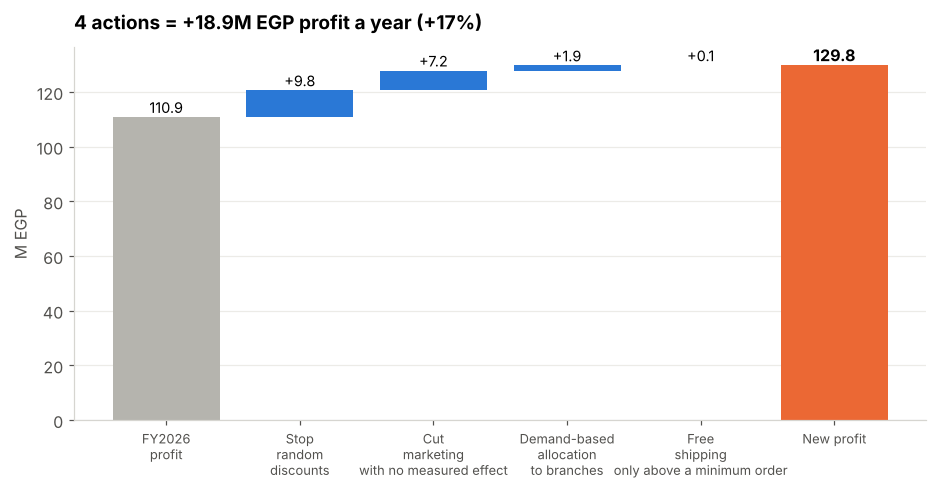

In [3]:
steps = [('FY2026 profit', pb['base'])] + list(zip(pb['actions'].action, pb['actions'].profit))
fig, ax = plt.subplots(figsize=(10, 4.4))
run = 0
labels = []
for i, (k, v) in enumerate(steps):
    ax.bar(i, v / 1e6, bottom=0 if i == 0 else run / 1e6, color=GREY if i == 0 else BLUE)
    ax.text(i, (run + v) / 1e6 + 1.5, f'{v / 1e6:+.1f}' if i else f'{v / 1e6:.1f}', ha='center', fontsize=9.5)
    run += v
    labels.append(k.replace(' ', '\n', 2))
ax.bar(len(steps), run / 1e6, color=ORANGE); ax.text(len(steps), run / 1e6 + 1.5, f'{run / 1e6:.1f}', ha='center', fontweight='bold')
ax.set_xticks(range(len(steps) + 1)); ax.set_xticklabels(labels + ['New profit'], fontsize=8.5)
style(ax, f"4 actions = +{(pb['new'] - pb['base']) / 1e6:.1f}M EGP profit a year (+{pb['uplift_pct']:.0f}%)", 'M EGP')
save(fig, 'c09_profit_bridge')

In [4]:
print(f"FY2027 scenarios (pieces grow {pb['growth']:.1f}% like FY2026, prices flat):")
print(f"breakeven: stopping discounts stays profitable unless we lose more than {pb['breakeven_volume_loss']:.1f}% of volume (evidence says ~0%)")
pb['scenarios'].assign(profit_M=lambda d: (d.profit / 1e6).round(1))[['scenario', 'profit_M']]

FY2027 scenarios (pieces grow 9.3% like FY2026, prices flat):
breakeven: stopping discounts stays profitable unless we lose more than 8.1% of volume (evidence says ~0%)


,scenario,profit_M
0,A · do nothing,121.3
1,B · the plan,142.0
2,"C · the plan, and we lose 5% of volume",134.5


In [5]:
s = A.stock_facts(c)
print(f"cash, not profit: stock {M(s['stock_value'])} EGP = {s['months_cover']:.0f} months of sales vs a 3-month need of {M(s['need_value_3m'])}")
print(f"→ up to {M(s['stock_value'] - s['need_value_3m'])} EGP of cash IF the stock count is confirmed (not added to the profit bridge)")

cash, not profit: stock 346.0M EGP = 35 months of sales vs a 3-month need of 44.6M
→ up to 301.4M EGP of cash IF the stock count is confirmed (not added to the profit bridge)


## The story in 8 lines
1. **Growth:** sales ×15 in 7 years, but pieces only ×2.5 – prices did the rest; real growth slowed to +9% in FY2026.
2. **Margin:** fixed at 38% because cost is always 59% of price; the only thing that moves it is the discount.
3. **Discounts:** 54% of lines, random, sell no extra pieces → 13M EGP a year given away.
4. **Marketing:** a fixed ~29M budget, campaigns claim ×45 the real orders, spend has no link with orders.
5. **Distribution:** branches get a fixed 1.6M pieces a year (×2.4 of sales), the wrong mix (socks 55% vs 27%).
6. **Purchasing:** a fixed ~42M pieces a year, equal for every SKU → the AI forecast says ~183K for Nov–Jan.
7. **The gap nobody asked about:** 9.3M pieces reached branches and are neither sold nor on the shelf.
8. **Trust:** 9 fields are random (delivery, payroll roles, return reasons…): we built nothing on them and listed what to collect.

**One sentence:** Cottonil does not need to sell more – it needs its decisions (discounts, marketing, buying, distribution) to follow real demand.